# 03 · Contrastive refinement (DDP, 2 GPUs)
Each aligned student (28, 14, 7 layers) is trained further on (query, positive, negative) triples so it ranks
the right passage first, not only lands near the teacher query vector.

The **document side is frozen**: documents are the teacher's `corpus.npy` vectors from `01`, never re-encoded.
Only the student's query encoder trains (LoRA + head for the 28-layer one, every weight for the pruned ones).

Per GPU, for B queries, with every doc of the global batch (each query's positive + `n_neg` negatives, all ranks):
```
logits_i = [s(q_i, d_j) for all docs] ++ [s(q_i, q_j) for the other queries on this GPU]   / tau
masked   = q_i's other labelled positives, q_i itself, any negative with s > s(q_i, d_i+) + margin
L        = CE(logits, own positive) + l2_weight * ||q_i - teacher(q_i)||^2
```

Input: `01` (data + teacher vectors), `02` (students + metrics). Output (attach to `04`): `runs/<mode>/<student>_cr/`, `runs/<mode>/metrics.json`.

In [1]:
# setup: clone/pull the repo on Kaggle, put it on sys.path, install what's missing (re-run to pull latest code)
import os, sys, importlib.util
REPO_URL = "https://github.com/pyther-hub/hlm-poc.git"
ON_KAGGLE = os.path.exists("/kaggle/working")
REPO = "/kaggle/working/hlm-poc" if ON_KAGGLE else os.path.abspath("..")
if ON_KAGGLE:
    if not os.path.exists(REPO):
        !git clone -q {REPO_URL} {REPO}
    else:
        !git -C {REPO} pull -q
sys.path.insert(0, REPO)

# HF token (higher rate limits, faster downloads). Kaggle: Add-ons -> Secrets -> add "HF_TOKEN", attach to notebook.
# Spawned workers inherit os.environ. Locally: export HF_TOKEN or `huggingface-cli login`.
if ON_KAGGLE and "HF_TOKEN" not in os.environ:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print(f"HF_TOKEN secret not found ({type(e).__name__}): downloads stay unauthenticated")

import transformers
from packaging.version import Version
if Version(transformers.__version__) < Version("4.56"):  # Qwen3 + the dtype= kwarg
    !pip install -q -U "transformers>=4.56"
    print("transformers upgraded: restart the kernel, then re-run this cell")
for pkg in ("datasets", "pyarrow", "accelerate"):
    if importlib.util.find_spec(pkg) is None:
        !pip install -q {pkg}

# %load_ext autoreload
# %autoreload 2

## Control panel

In [2]:
import os
import shutil
import torch
from model import get_device
from teacher import TEACHER_DEFAULTS as T

DEBUG = False    
NPROCS = 2

# --- paths. On Kaggle, earlier notebooks' outputs are attached as inputs (read only); set the slugs to yours.
#     Off Kaggle everything lives under the repo, so every IN_* is the same dir.
ROOT = "/kaggle/working" if ON_KAGGLE else REPO
MODE = "debug" if DEBUG else "full"
KAGGLE_IN = "/kaggle/input/datasets/tensorpanda231"


IN_01 = f"{KAGGLE_IN}/corpus-teacher-embd" if ON_KAGGLE else REPO
IN_02 = f"//kaggle/input/datasets/tensorpanda231/student-aligned-models" if ON_KAGGLE else REPO
DATA_PATH = f"{IN_01}/cache/{MODE}/data.json"
EMB_DIR = f"{IN_01}/cache/{MODE}/emb/teacher"
RUN_DIR = f"{ROOT}/runs/{MODE}"
PREV_METRICS = f"{IN_02}/runs/{MODE}/metrics.json"

# --- students to refine: name -> checkpoint dir from 02 (row "<name>_cr" each)
STUDENTS = {n: f"{IN_02}/runs/{MODE}/{n}/final" for n in ("aligned", "prog_l14", "prog_l7")}

# --- refinement (refine.REFINE_DEFAULTS; init_adapter / out_dir set per student)
REFINE = dict(dim=T["dim"], query_prefix="", max_query_len=32,   # same as 02
              tau=0.05,                            # temperature
              margin=0.2,                          # mask negatives with s > s(q, d+) + margin (likely false negatives)
              n_neg=3,                             # negatives per query: 1 = stored one, k > 1 adds k-1 teacher-mined
              l2_weight=0.1,                       # keeps the student near the teacher query space; 0 = pure L_CR
              lr=5e-5, head_lr=1e-4, weight_decay=0.0, warmup_ratio=0.05,
              epochs=1, batch_size=96,             # queries per GPU; docs per step = (1 + n_neg) * batch_size * NPROCS
              grad_clip=1.0, amp=True, seed=0,
              log_every=20, eval_every=200, save_every=500, keep_last=2,
              data_path=DATA_PATH, teacher_emb_dir=EMB_DIR)

# --- evaluation (evaluation.evaluate_model kwargs): student queries vs the frozen teacher corpus, top 100
EVAL = dict(splits=("val", "test"), dim=T["dim"], max_query_len=32, query_prefix="", device=get_device(), dtype="fp16")

if DEBUG:
    REFINE.update(log_every=5, eval_every=20, save_every=20)

## 1 · Check inputs

In [3]:
from data import load_json
from evaluation import load_index

# rows accumulate across notebooks: start from the previous notebook's metrics.json (copied once)
os.makedirs(RUN_DIR, exist_ok=True)
if not os.path.exists(f"{RUN_DIR}/metrics.json") and os.path.exists(PREV_METRICS):
    shutil.copy(PREV_METRICS, f"{RUN_DIR}/metrics.json")
data = load_json(DATA_PATH)
index = load_index(data, EMB_DIR, ("val", "test"))
assert set(data["train"]["ids"]) <= set(data["align"]["ids"]), "train queries need teacher vectors (align set)"
for name, path in STUDENTS.items():
    cfg = load_json(f"{path}/adapter_config.json")
    assert cfg["out_dim"] == T["dim"]
    print(f"{name:<9} layers {len(cfg.get('keep_layers', range(28)))}  full fine-tune: {cfg.get('full', False)}")
per_step = REFINE["batch_size"] * NPROCS
print(f"{len(data['train']['ids'])} train queries, {len(data['train']['ids']) // per_step} steps per student")

[eval] index ok: corpus (299985, 256), val (5000, 256), test (5000, 256)
aligned   layers 28  full fine-tune: False
prog_l14  layers 14  full fine-tune: True
prog_l7   layers 7  full fine-tune: True
90000 train queries, 468 steps per student


## 2 · The training triples
Each train query comes with its labelled positive(s) and the stored negative (`negative_passages[0]`, not verified BM25).

In [4]:
corpus = data["corpus"]["texts"]
for i in range(3):
    print(f"query    {data['train']['texts'][i]}")
    print(f"positive {corpus[data['train']['pos'][i][0]][:200]}")
    print(f"negative {corpus[data['train']['neg'][i]][:200]}\n")
    

query    what causes glomerulonephritis
positive In children, a common cause of glomerulonephritis is from a streptococcal infection, such as strep throat or upper respiratory infection. Glomerulonephritis usually occurs more than one week after an 
negative Microscopic polyangiitis (also known as microscopic polyarteritism, Microscopic polyarteritis nodosa, MPA) is an ill-defined autoimmune disease characterized by a systemic, pauci-immune, necrotizing, 

query    what county is bartlesville ok located in
positive Bartlesville is a city mostly in Washington County in the U.S. state of Oklahoma. The population was 35,750 at the 2010 census, with a 2013 estimate of 36,258 according to the US Census Bureau. Bartle
negative The government of a county is located at the county seat, a city or town where court sessions are held and duties are performed by county officers.

query    how to become uber driver
positive How to become an uber driver â Uber is an app based taxi company with its 

## 3 · Refine every student, compare with its pre-refinement checkpoint
Trains the missing `<name>_cr` arms, evaluates the missing rows, prints the gain per student and the table.

In [5]:
# print(STUDENTS)

[rank1] joined process group on cuda:1 (14.5/14.6 GB free)[rank0] joined process group on cuda:0 (14.5/14.6 GB free)

[rank1] waiting for rank 0 to load the model
[rank0] loading //kaggle/input/datasets/tensorpanda231/student-aligned-models/runs/full/aligned/final


Loading weights: 100%|██████████| 310/310 [00:00<00:00, 418.46it/s]


[rank0] model loaded on cuda:0 (12.1/14.6 GB free)


/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
[rank0]:[W1029 04:05:27.021857479 ProcessGroupNCCL.cpp:5188] Guessing device ID based on global rank. This can cause a hang if rank to GPU mapping is heterogeneous. You can specify device_id in init_process_group()


[rank1] loading //kaggle/input/datasets/tensorpanda231/student-aligned-models/runs/full/aligned/final
[rank0] corpus on cuda:0 (11.9/14.6 GB free), mining negatives


...

[eval] aligned_cr -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[eval] prog_l14_cr -> /kaggle/working/runs/full/metrics.json


Loading weights:   0%|          | 0/310 [00:00<?, ?it/s]

[eval] prog_l7_cr -> /kaggle/working/runs/full/metrics.json
aligned        CR gain: recall@100 +0.0069  ndcg@10 +0.0331
prog_l14       CR gain: recall@100 +0.0099  ndcg@10 +0.0207
prog_l7        CR gain: recall@100 +0.0279  ndcg@10 +0.0546
split=test
run                    recall@100  recall@10    ndcg@10     mrr@10  retention
teacher                    0.9928     0.9457     0.8063     0.7639     1.0000
aligned                    0.9707     0.8636     0.6975     0.6486     0.8651
aligned_cr                 0.9776     0.8855     0.7306     0.6848     0.9061
prog_l14                   0.9479     0.8136     0.6410     0.5900     0.7951
prog_l14_cr                0.9578     0.8305     0.6617     0.6117     0.8207
prog_l7                    0.9098     0.7253     0.5470     0.4947     0.6784
prog_l7_cr                 0.9377     0.7824     0.6015     0.5479     0.7461


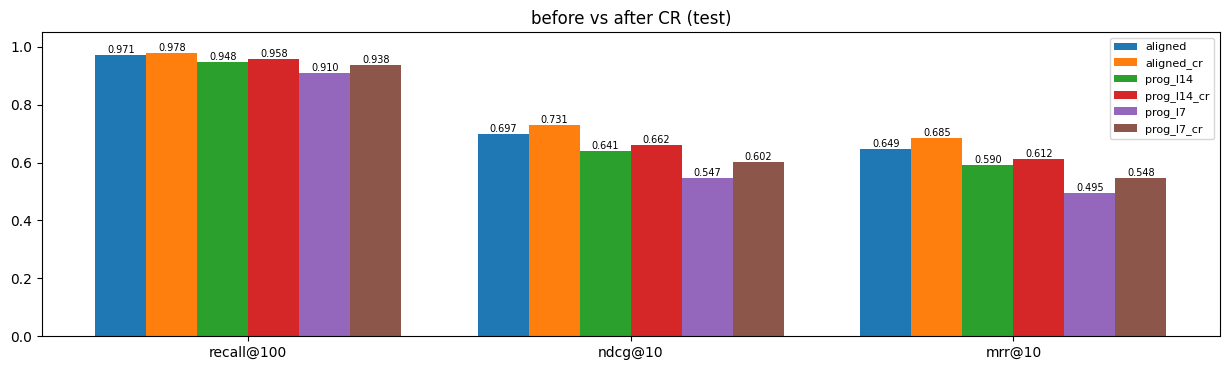

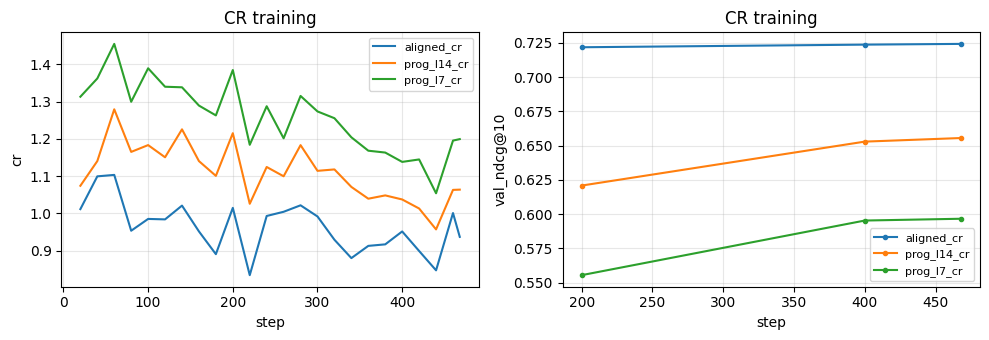

In [6]:
import matplotlib.pyplot as plt
from IPython.display import display
from run_exp import exp_cr

res = exp_cr(REFINE, STUDENTS, data, index, RUN_DIR, EVAL, NPROCS)
for fig in res["figs"]:
    display(fig)
plt.close("all")